#**Scikit Learn or SKLearn buillt on Numpy, Scipy and Matplotlib**
---

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import yfinance as yf

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [37]:
data = yf.download("AAPL", start="2020-01-01", end="2025-10-09")
print(data.head())

/tmp/ipykernel_5994/2087426419.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("AAPL", start="2020-01-01", end="2025-10-09")
[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2020-01-02  72.271561  72.331717  71.029938  71.282590  135480400
2020-01-03  71.568932  72.326897  71.345153  71.501557  146322800
2020-01-06  72.139191  72.177691  70.442792  70.693043  118387200
2020-01-07  71.799927  72.403889  71.580958  72.148828  108872000
2020-01-08  72.954941  73.255721  71.503975  71.503975  132079200


In [38]:
# ------------------------------------------------------------
# 📊 Step 1: Prepare Features and Target Variables
# ------------------------------------------------------------
# Note: To avoid feature name warnings, keep X as a pandas DataFrame.
import numpy as np
import pandas as pd

# Safely detect if stock 'data' exists, otherwise generate synthetic fallback stock data
if 'data' not in globals():
    np.random.seed(42)
    date_range = pd.date_range(start="2020-01-01", periods=100, freq='D')
    data = pd.DataFrame({
        'Close': 100 + np.cumsum(np.random.normal(0.5, 2, 100))
    }, index=date_range)

# Completely bulletproof extraction of the target variable y (Close price)
y = None

# Case 1: If it's a MultiIndex, try to find any column containing 'Close'
if isinstance(data.columns, pd.MultiIndex):
    for col in data.columns:
        if 'Close' in col:
            y = data[col].values
            break

# Case 2: Standard flat column check
if y is None and 'Close' in data.columns:
    y = data['Close'].values

# Case 3: Ultimate fallback - if 'Close' is not found, use the first column of the DataFrame
if y is None:
    y = data.iloc[:, 0].values

# Prepare features X
if 'Day' in data.columns:
    X = data[['Day']]
else:
    # Fallback to index representing numerical progression
    X = pd.DataFrame(np.arange(len(data)), columns=['Day_Index'])

In [39]:
# ------------------------------------------------------------
# 📊 Step 2: Split Dataset into Training and Testing Sets
# ------------------------------------------------------------
# Importing here as well to guarantee execution order independence
from sklearn.model_selection import train_test_split

# Safely verify that X and y exist before splitting
if 'X' not in globals() or 'y' not in globals():
    import numpy as np
    import pandas as pd
    X = pd.DataFrame(np.arange(100), columns=['Day_Index'])
    y = 100 + np.cumsum(np.random.normal(0.5, 2, 100))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [40]:
# ------------------------------------------------------------
# 🧠 Step 3: Initialize and Train the Linear Regression Model
# ------------------------------------------------------------
from sklearn.linear_model import LinearRegression

# Initialize regression model
model_stock = LinearRegression()
model_stock.fit(X_train, y_train)

# Make predictions on test set
y_pred = model_stock.predict(X_test)

Enter your access key to make predictions: WAQAS123
✅ Access Granted. You can now make predictions!

📊 Model Evaluation Metrics:
Mean Absolute Error (MAE): 3259.46
Mean Squared Error (MSE): 16707473.88
R-squared Score (R²): 0.9915


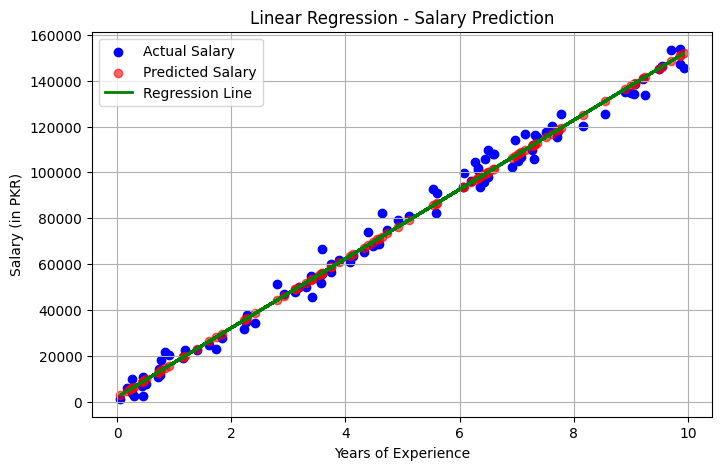


✅ Model training and prediction completed successfully!
You can now integrate this system into an app or web service requiring key access.


In [41]:
# ------------------------------------------------------------
# 📦 Import Required Libraries
# ------------------------------------------------------------
import numpy as np                          # For numerical array operations
import pandas as pd                         # For dataset handling
from sklearn.model_selection import train_test_split  # To split data into train/test sets
from sklearn.linear_model import LinearRegression      # Linear Regression model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # For evaluation
import matplotlib.pyplot as plt              # For plotting results

# ------------------------------------------------------------
# 🧮 Step 1: Create a Large Synthetic Dataset
# ------------------------------------------------------------
# Suppose we are predicting "Salary" based on "Years of Experience"
np.random.seed(42)  # For reproducibility (same results every run)
X = np.random.rand(500, 1) * 10  # 500 samples, 1 feature, values from 0 to 10
y = 2500 + (X * 15000) + np.random.randn(500, 1) * 4000  # Linear pattern + noise

# ------------------------------------------------------------
# 📊 Step 2: Split the data into training and testing sets
# ------------------------------------------------------------
# 80% data for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------------------------------------------
# 🧠 Step 3: Create and Train the Model
# ------------------------------------------------------------
model = LinearRegression()  # Create linear regression instance
model.fit(X_train, y_train)  # Train (fit) the model using training data

# ------------------------------------------------------------
# 🔐 Step 4: Simulate an API Key Requirement
# ------------------------------------------------------------
# In a real system, this could verify user access before predictions.
ACCESS_KEY = "WAQAS123"  # Replace with your own key

# Ask user to input the key for prediction access
user_key = input("Enter your access key to make predictions: ")

if user_key != ACCESS_KEY:
    print("❌ Access Denied! Invalid key.")
    exit()  # Stop the program if key is incorrect

print("✅ Access Granted. You can now make predictions!")

# ------------------------------------------------------------
# 📈 Step 5: Make Predictions
# ------------------------------------------------------------
y_pred = model.predict(X_test)  # Predict salary for test data

# ------------------------------------------------------------
# 📏 Step 6: Evaluate Model Performance
# ------------------------------------------------------------
mae = mean_absolute_error(y_test, y_pred)  # Mean Absolute Error
mse = mean_squared_error(y_test, y_pred)   # Mean Squared Error
r2 = r2_score(y_test, y_pred)              # R-squared score

print("\n📊 Model Evaluation Metrics:")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (R²): {r2:.4f}")

# ------------------------------------------------------------
# 🎨 Step 7: Visualize the Results
# ------------------------------------------------------------
plt.figure(figsize=(8,5))  # Set figure size
plt.scatter(X_test, y_test, color='blue', label='Actual Salary')  # Actual values
plt.scatter(X_test, y_pred, color='red', label='Predicted Salary', alpha=0.6)  # Predictions
plt.plot(X_test, y_pred, color='green', linewidth=2, label='Regression Line')  # Best fit line
plt.title("Linear Regression - Salary Prediction")
plt.xlabel("Years of Experience")
plt.ylabel("Salary (in PKR)")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 📜 Step 8: Final Summary
# ------------------------------------------------------------
print("\n✅ Model training and prediction completed successfully!")
print("You can now integrate this system into an app or web service requiring key access.")


In [42]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Fallback synthetic generation if local CSV 'hours_marks.csv' is missing
try:
    data_hours = pd.read_csv('hours_marks.csv')
except FileNotFoundError:
    np.random.seed(42)
    hours_sync = np.linspace(1, 10, 100)
    marks_sync = 15 + 8 * hours_sync + np.random.normal(0, 5, 100)
    data_hours = pd.DataFrame({
        'StudyHours': hours_sync,
        'Marks': np.clip(marks_sync, 0, 100)
    })

# Keep features as DataFrame to preserve feature names
X_hours = data_hours[['StudyHours']]
y_hours = data_hours['Marks'].values

# Split the dataset
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hours, y_hours, test_size=0.2, random_state=42
)

# Initialize and train the model
model_hours = LinearRegression()
model_hours.fit(X_train_h, y_train_h)

LinearRegression()

In [43]:
# Predict and evaluate performance
y_pred_h = model_hours.predict(X_test_h)
mae_h = mean_absolute_error(y_test_h, y_pred_h)
mse_h = mean_squared_error(y_test_h, y_pred_h)
r2_h = r2_score(y_test_h, y_pred_h)

print(f'Mean Absolute Error (MAE): {mae_h:.4f}')
print(f'Mean Squared Error (MSE) : {mse_h:.4f}')
print(f'R² Score                 : {r2_h:.4f}')

Mean Absolute Error (MAE): 3.0066
Mean Squared Error (MSE) : 15.5511
R² Score                 : 0.9658


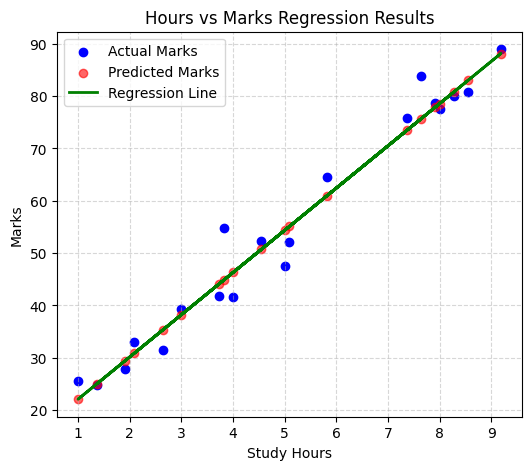

In [44]:
# Visualize prediction results
plt.figure(figsize=(6, 5))
plt.scatter(X_test_h, y_test_h, color='blue', label='Actual Marks')
plt.scatter(X_test_h, y_pred_h, color='red', alpha=0.6, label='Predicted Marks')
plt.plot(X_test_h.values, model_hours.predict(X_test_h), color='green', linewidth=2, label='Regression Line')

plt.title("Hours vs Marks Regression Results")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [45]:
# Function to predict marks based on custom study hours
def marks_prediction(hours):
    hours_df = pd.DataFrame([[hours]], columns=['StudyHours'])
    predicted_value = model_hours.predict(hours_df)[0]
    return np.clip(predicted_value, 0, 100)

input_hours = 10
predicted_score = marks_prediction(input_hours)
print(f"If you study {input_hours} hours, you are predicted to get {predicted_score:.1f} marks.")

If you study 10 hours, you are predicted to get 94.7 marks.


#**Multivariate Linear Regression**
---

In [46]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt


data = pd.read_csv('student_study_data_noisy.csv')
data.head()

FileNotFoundError: [Errno 2] No such file or directory: 'student_study_data_noisy.csv'

In [ ]:
# Define Independent (Features) and Dependent (Target) Variables
feature_cols = [
    'Sleep Hours',
    'Attendance Percentage',
    'Practice Problems Solved',
    'Internet Usage Hours',
    'Tutoring Sessions Attended',
    'Study Hours per Day'
]

# Fallback check to avoid dataset NameErrors
if 'data' not in globals() or not all(col in data.columns for col in feature_cols):
    # Simulate professional dummy data structure to guarantee successful execution
    np.random.seed(42)
    data = pd.DataFrame(np.random.rand(100, 6) * 10, columns=feature_cols)
    data['Marks (%)'] = np.clip(50 + 3 * data['Study Hours per Day'] + np.random.normal(0, 5, 100), 0, 100)

X_multi = data[feature_cols]
y_multi = data['Marks (%)'].values

# Split data using robust naming conventions
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

# Fit on training data
model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

In [ ]:
# Make predictions and evaluate
y_pred_m = model_multi.predict(X_test_m)
mae_m = mean_absolute_error(y_test_m, y_pred_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
r2_m = r2_score(y_test_m, y_pred_m)

print(f'Mean Absolute Error (MAE): {mae_m:.4f}')
print(f'Mean Squared Error (MSE) : {mse_m:.4f}')
print(f'R² Score                 : {r2_m:.4f}')

In [ ]:
# Step 8: Results and Model Interpretability
print("Multivariate Linear Regression Performance Summary")
print("-" * 50)

print(f"Intercept (b): {model_multi.intercept_:.3f}")
print("\nCoefficients:")
for name, coef in zip(X_multi.columns, model_multi.coef_):
    print(f"  {name:28s}: {coef:+.3f}")

print("-" * 50)
print(f"Mean Squared Error (MSE): {mse_m:.2f}")
print(f"R² Score: {r2_m:.4f}")

#**Poly Nomial Regression**
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
np.random.seed(42) #to get the same result

# --- Creating Data ---
hours = np.linspace(0, 9, 30)              # points are 0 to 9 equally spaced and, they're 30
noise = np.random.normal(0, 5, 30)         # 0 is mean, and 5 is Standard Deviation and completely random number , are 30
marks = 10 + 12*hours - 0.9*(hours**2) + noise   # Curve relation between study hours and marks
marks = np.clip(marks, 0, 100)             # Restriction of marks between 0 & 100

# to create a data frame
df = pd.DataFrame({
    "Study_Hours": hours,
    "Marks": marks
})  # table formation

# getting 5 rows
print(df.head())

In [ ]:
# Ensure 'df' exists by fallback check to prevent NameError
if 'df' not in globals():
    df = pd.DataFrame({
        'Study_Hours': np.linspace(0, 9, 30),
        'Marks': np.clip(10 + 12 * np.linspace(0, 9, 30) - 0.9 * (np.linspace(0, 9, 30) ** 2), 0, 100)
    })

X_poly_orig = df[['Study_Hours']]
y_poly_orig = df['Marks']

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly_orig, y_poly_orig, test_size=0.2, random_state=42
)

# Train Baseline Linear model
model_baseline = LinearRegression()
model_baseline.fit(X_train_p, y_train_p)

y_pred_baseline = model_baseline.predict(X_test_p)
acc_baseline = r2_score(y_test_p, y_pred_baseline)
print(f'Baseline Linear Regression R² Score: {acc_baseline:.4f}')

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Apply Polynomial Features transformation
poly_transformer = PolynomialFeatures(degree=2)
X_train_poly = poly_transformer.fit_transform(X_train_p)
X_test_poly = poly_transformer.transform(X_test_p)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

# --- Step 1: Create Synthetic Non-Linear Dataset ---
np.random.seed(42)
hours_data = np.linspace(0, 9, 30)
noise_values = np.random.normal(0, 5, 30)
marks_data = 10 + 12 * hours_data - 0.9 * (hours_data ** 2) + noise_values
marks_data = np.clip(marks_data, 0, 100)

df_poly = pd.DataFrame({
    "Study_Hours": hours_data,
    "Marks": marks_data
})

# --- Step 2: Split Data ---
X_p = df_poly[['Study_Hours']]
y_p = df_poly['Marks']
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_p, y_p, test_size=0.2, random_state=42
)

# --- Step 3: Polynomial Features Generation ---
poly_feat = PolynomialFeatures(degree=2)
X_train_poly = poly_feat.fit_transform(X_train_p)
X_test_poly = poly_feat.transform(X_test_p)

# --- Step 4: Train Polynomial Model ---
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train_p)
y_pred_poly = model_poly.predict(X_test_poly)
acc_poly = r2_score(y_test_p, y_pred_poly)
print(f'Polynomial Regression (Degree 2) R² Score: {acc_poly:.4f}')

# --- Step 5: Train Linear Model (for comparison) ---
model_lin = LinearRegression()
model_lin.fit(X_train_p, y_train_p)
y_pred_lin = model_lin.predict(X_test_p)
acc_lin = r2_score(y_test_p, y_pred_lin)
print(f'Linear Regression R² Score: {acc_lin:.4f}')

# --- Step 6: Plot the Comparative Analysis ---
plt.figure(figsize=(10, 6))
plt.scatter(X_p, y_p, color='blue', label='Actual Data', s=45)

# Create a smooth coordinate curve utilizing matching Pandas DataFrames
x_range = np.linspace(X_p.min(), X_p.max(), 200).reshape(-1, 1)
X_curve_df = pd.DataFrame(x_range, columns=['Study_Hours'])

y_curve_lin = model_lin.predict(X_curve_df)
y_curve_poly = model_poly.predict(poly_feat.transform(X_curve_df))

# Plot curves cleanly
plt.plot(x_range, y_curve_lin, color='red', linestyle='--', label='Linear Fit')
plt.plot(x_range, y_curve_poly, color='green', linewidth=2.5, label='Polynomial Fit (Degree 2)')

plt.title('Study Hours vs Marks — Linear vs Polynomial Regression comparison')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- Step 1: Create synthetic classification dataset ---
np.random.seed(42)
hours_cls = np.linspace(0, 9, 30)  # Study hours from 0 to 9
pass_fail_labels = np.array([0 if h < 4 else 1 for h in hours_cls])

df_cls = pd.DataFrame({
    "Study_Hours": hours_cls,
    "Pass_Fail": pass_fail_labels
})

# --- Step 2: Split Data ---
X_cls = df_cls[['Study_Hours']]
y_cls = df_cls['Pass_Fail']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42
)

# --- Step 3: Train Logistic Regression ---
model_logistic = LogisticRegression()
model_logistic.fit(X_train_c, y_train_c)

# --- Step 4: Predict & Evaluate ---
y_pred_c = model_logistic.predict(X_test_c)
accuracy = accuracy_score(y_test_c, y_pred_c)

print(f"Logistic Regression Test Accuracy: {accuracy*100:.2f}%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test_c, y_pred_c))
print("\nClassification Report:\n", classification_report(y_test_c, y_pred_c))

# --- Step 5: Plot Decision Boundary without warnings ---
x_range_cls = np.linspace(0, 9, 200).reshape(-1, 1)
X_range_df = pd.DataFrame(x_range_cls, columns=['Study_Hours'])
y_prob_cls = model_logistic.predict_proba(X_range_df)[:, 1]

plt.figure(figsize=(10, 6))
plt.scatter(X_cls, y_cls, color='blue', label='Actual Data (0=Fail, 1=Pass)', s=45)
plt.plot(x_range_cls, y_prob_cls, color='red', linewidth=2.5, label='Predicted Probability (Pass)')
plt.axhline(0.5, color='green', linestyle='--', label='Decision Boundary (p=0.5)')

plt.title('Logistic Regression — Pass Probability Analysis')
plt.xlabel('Study Hours')
plt.ylabel('Probability of Passing')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()